In [51]:
import pandas as pd

In [52]:
df_mut = pd.read_csv('../data/mutaciones/mut_gen_cancer_type_STKR.csv')
df_mut

,tipo_cancer,Gen_names,mutation_count,mutation_frequency
0,Cabeza,ACVR1,5,0.004950
1,Cabeza,ACVR1B,19,0.018812
2,Cabeza,ACVR1C,27,0.026733
3,Cabeza,ACVR2A,5,0.004950
4,Cabeza,ACVR2B,3,0.002970
...,...,...,...,...
181,Vejiga,BMPR1A,2,0.001980
182,Vejiga,BMPR1B,12,0.011881
183,Vejiga,BMPR2,11,0.010891
184,Vejiga,TGFBR1,32,0.031683


In [53]:
df_xena_exp = pd.read_csv('../data/Xena API/clineexp_long_STKR.csv')
df_xena_exp

,_primary_site,_sample_type,Gene,Normalized Expression
0,Uterus,Primary Tumor,BMPR1B,8.983
1,Uterus,Primary Tumor,BMPR1B,8.654
2,Uterus,Primary Tumor,BMPR1B,9.812
3,Uterus,Primary Tumor,BMPR1B,7.580
4,Uterus,Primary Tumor,BMPR1B,9.510
...,...,...,...,...
129151,Ovary,Normal Tissue,ACVR1C,9.777
129152,Ovary,Normal Tissue,ACVR1C,9.054
129153,Ovary,Normal Tissue,ACVR1C,7.266
129154,Ovary,Normal Tissue,ACVR1C,4.632


In [54]:
exp_tumor = df_xena_exp.loc[(df_xena_exp['_sample_type']=='Primary Tumor')] 

In [55]:
exp_tumor

,_primary_site,_sample_type,Gene,Normalized Expression
0,Uterus,Primary Tumor,BMPR1B,8.9830
1,Uterus,Primary Tumor,BMPR1B,8.6540
2,Uterus,Primary Tumor,BMPR1B,9.8120
3,Uterus,Primary Tumor,BMPR1B,7.5800
4,Uterus,Primary Tumor,BMPR1B,9.5100
...,...,...,...,...
125588,Bladder,Primary Tumor,ACVR1C,7.4070
125589,Bladder,Primary Tumor,ACVR1C,1.6900
125590,Bladder,Primary Tumor,ACVR1C,2.5650
125591,Bladder,Primary Tumor,ACVR1C,0.8506


In [56]:
exp_tumor_mean = exp_tumor.groupby(['Gene','_primary_site', '_sample_type'])['Normalized Expression'].agg(['mean', 'std']).reset_index()
exp_tumor_mean

,Gene,_primary_site,_sample_type,mean,std
0,ACVR1,Bladder,Primary Tumor,9.797885,0.755207
1,ACVR1,Brain,Primary Tumor,10.100094,0.450888
2,ACVR1,Breast,Primary Tumor,10.510159,0.605623
3,ACVR1,Cervix,Primary Tumor,10.065655,0.684176
4,ACVR1,Colon,Primary Tumor,9.837003,0.449312
...,...,...,...,...,...
175,TGFBR2,Pancreas,Primary Tumor,12.919663,0.722799
176,TGFBR2,Prostate,Primary Tumor,11.064659,0.914741
177,TGFBR2,Skin,Primary Tumor,11.531186,1.076080
178,TGFBR2,Stomach,Primary Tumor,12.710051,0.946084


In [57]:


from deep_translator import GoogleTranslator
import pandas as pd


# Traducir la columna
df_mut['ColumnaTraducida'] = df_mut['tipo_cancer'].apply(lambda x: GoogleTranslator(source='auto', target='en').translate(x))

df_mut


,tipo_cancer,Gen_names,mutation_count,mutation_frequency,ColumnaTraducida
0,Cabeza,ACVR1,5,0.004950,Head
1,Cabeza,ACVR1B,19,0.018812,Head
2,Cabeza,ACVR1C,27,0.026733,Head
3,Cabeza,ACVR2A,5,0.004950,Head
4,Cabeza,ACVR2B,3,0.002970,Head
...,...,...,...,...,...
181,Vejiga,BMPR1A,2,0.001980,Bladder
182,Vejiga,BMPR1B,12,0.011881,Bladder
183,Vejiga,BMPR2,11,0.010891,Bladder
184,Vejiga,TGFBR1,32,0.031683,Bladder


In [58]:
df_mut.loc[df_mut['ColumnaTraducida']=='Head', 'ColumnaTraducida'] = 'Head and Neck region'
df_mut

,tipo_cancer,Gen_names,mutation_count,mutation_frequency,ColumnaTraducida
0,Cabeza,ACVR1,5,0.004950,Head and Neck region
1,Cabeza,ACVR1B,19,0.018812,Head and Neck region
2,Cabeza,ACVR1C,27,0.026733,Head and Neck region
3,Cabeza,ACVR2A,5,0.004950,Head and Neck region
4,Cabeza,ACVR2B,3,0.002970,Head and Neck region
...,...,...,...,...,...
181,Vejiga,BMPR1A,2,0.001980,Bladder
182,Vejiga,BMPR1B,12,0.011881,Bladder
183,Vejiga,BMPR2,11,0.010891,Bladder
184,Vejiga,TGFBR1,32,0.031683,Bladder


In [59]:
merge_corr = exp_tumor_mean.merge(df_mut, left_on=['Gene', '_primary_site'], right_on=['Gen_names', 'ColumnaTraducida'])
merge_corr.sort_values(by='mutation_count', ascending=False)

,Gene,_primary_site,_sample_type,mean,std,tipo_cancer,Gen_names,mutation_count,mutation_frequency,ColumnaTraducida
128,TGFBR1,Colon,Primary Tumor,10.689406,0.748018,Colon,TGFBR1,86,0.085149,Colon
68,ACVRL1,Lung,Primary Tumor,9.682132,0.900698,Pulmon,ACVRL1,63,0.062376,Lung
18,ACVR1B,Lung,Primary Tumor,11.097222,0.707303,Pulmon,ACVR1B,63,0.062376,Lung
30,ACVR1C,Lung,Primary Tumor,6.317033,1.807117,Pulmon,ACVR1C,57,0.056436,Lung
14,ACVR1B,Colon,Primary Tumor,11.401278,0.593531,Colon,ACVR1B,56,0.055446,Colon
...,...,...,...,...,...,...,...,...,...,...
50,ACVR2B,Breast,Primary Tumor,9.263777,0.802409,Seno,ACVR2B,1,0.000990,Breast
58,ACVR2B,Prostate,Primary Tumor,9.093261,0.608314,Prostata,ACVR2B,1,0.000990,Prostate
35,ACVR2A,Bladder,Primary Tumor,9.262174,0.900306,Vejiga,ACVR2A,1,0.000990,Bladder
2,ACVR1,Breast,Primary Tumor,10.510159,0.605623,Seno,ACVR1,1,0.000990,Breast


In [60]:
merge_corr['_primary_site'].unique()


array(['Bladder', 'Brain', 'Breast', 'Colon', 'Head and Neck region',
       'Liver', 'Lung', 'Ovary', 'Pancreas', 'Stomach', 'Cervix',
       'Kidney', 'Prostate'], dtype=object)

In [61]:
merge_corr['tipo_cancer'].unique()

array(['Vejiga', 'Cerebro', 'Seno ', 'Colon', 'Cabeza', 'Higado',
       'Pulmon', 'Ovario', 'Pancreas', 'Estomago', 'Cervix', 'Riñon',
       'Prostata'], dtype=object)

In [62]:
merge_corr['ColumnaTraducida'].unique()

array(['Bladder', 'Brain', 'Breast', 'Colon', 'Head and Neck region',
       'Liver', 'Lung', 'Ovary', 'Pancreas', 'Stomach', 'Cervix',
       'Kidney', 'Prostate'], dtype=object)

In [81]:
import numpy as np

# Calcular el logaritmo base 10 de la columna 'mean'
merge_corr['log_mean'] = np.log10(merge_corr['mean'])
merge_corr['mutation_count_log'] = np.log10(merge_corr['mutation_count'])
merge_corr

,Gene,_primary_site,_sample_type,mean,std,tipo_cancer,Gen_names,mutation_count,mutation_frequency,ColumnaTraducida,log_mean,mutation_count_log
0,ACVR1,Bladder,Primary Tumor,9.797885,0.755207,Vejiga,ACVR1,7,0.006931,Bladder,0.991132,0.845098
1,ACVR1,Brain,Primary Tumor,10.100094,0.450888,Cerebro,ACVR1,6,0.005941,Brain,1.004325,0.778151
2,ACVR1,Breast,Primary Tumor,10.510159,0.605623,Seno,ACVR1,1,0.000990,Breast,1.021609,0.000000
3,ACVR1,Colon,Primary Tumor,9.837003,0.449312,Colon,ACVR1,7,0.006931,Colon,0.992863,0.845098
4,ACVR1,Head and Neck region,Primary Tumor,10.629529,0.743498,Cabeza,ACVR1,5,0.004950,Head and Neck region,1.026514,0.698970
...,...,...,...,...,...,...,...,...,...,...,...,...
143,TGFBR2,Kidney,Primary Tumor,12.734579,1.079851,Riñon,TGFBR2,4,0.003960,Kidney,1.104985,0.602060
144,TGFBR2,Lung,Primary Tumor,11.831214,1.111772,Pulmon,TGFBR2,24,0.023762,Lung,1.073029,1.380211
145,TGFBR2,Ovary,Primary Tumor,11.220501,1.003001,Ovario,TGFBR2,2,0.001980,Ovary,1.050012,0.301030
146,TGFBR2,Pancreas,Primary Tumor,12.919663,0.722799,Pancreas,TGFBR2,40,0.039604,Pancreas,1.111251,1.602060


In [80]:
import altair as alt

alt.Chart(merge_corr).transform_calculate(
).mark_point().encode(
    x='mutation_count',
    y='mean',
    #color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['Gene']
)

alt.Chart(...)

In [1]:
import altair as alt


alt.Chart(merge_corr).transform_calculate(
).mark_point().encode(
    x='mutation_count_log',
    y='log_mean',
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['Gene']
)

NameError: name 'merge_corr' is not defined

## Estadistica logaritmo

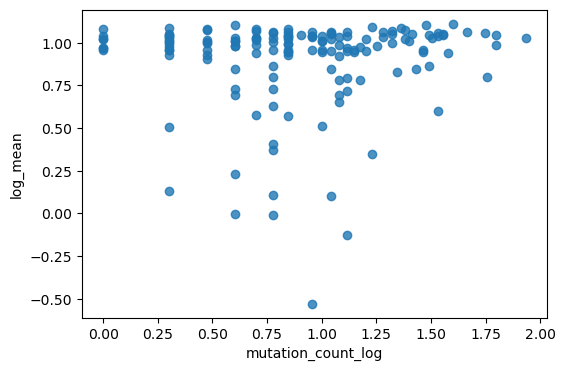

In [88]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_corr['mutation_count_log'], y=merge_corr['log_mean'], alpha=0.8)

ax.set_xlabel('mutation_count_log')
ax.set_ylabel('log_mean')
plt.show()


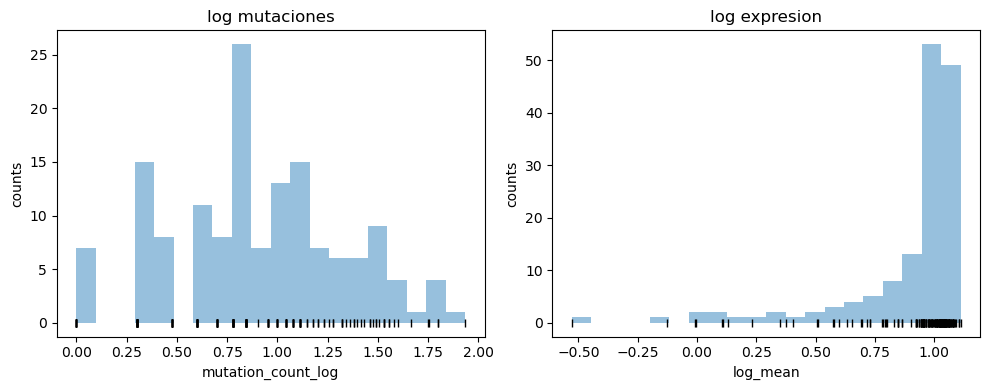

In [90]:
# Gráfico distribución variables
# ==============================================================================
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

axs[0].hist(x=merge_corr['mutation_count_log'], bins=20, color="#3182bd", alpha=0.5)
axs[0].plot(merge_corr['mutation_count_log'], np.full_like(merge_corr['mutation_count_log'], -0.01), '|k', markeredgewidth=1)
axs[0].set_title('log mutaciones')
axs[0].set_xlabel('mutation_count_log')
axs[0].set_ylabel('counts')

axs[1].hist(x=merge_corr['log_mean'], bins=20, color="#3182bd", alpha=0.5)
axs[1].plot(merge_corr['log_mean'], np.full_like(merge_corr['log_mean'], -0.01), '|k', markeredgewidth=1)
axs[1].set_title('log expresion')
axs[1].set_xlabel('log_mean')
axs[1].set_ylabel('counts')


plt.tight_layout();

In [91]:
import statsmodels.api as sm
import pingouin as pg
from scipy import stats
from scipy.stats import pearsonr

# Cálculo de correlación, significancia e intervalos con pingouin
# ==============================================================================
display(pg.corr(merge_corr['mutation_count_log'], merge_corr['log_mean'], method='pearson'))
display(pg.corr(merge_corr['mutation_count_log'], merge_corr['log_mean'], method='spearman'))
display(pg.corr(merge_corr['mutation_count_log'], merge_corr['log_mean'], method='kendall'))

,n,r,CI95%,p-val,BF10,power
pearson,148,0.050564,"[-0.11, 0.21]",0.541652,0.124,0.093651


,n,r,CI95%,p-val,power
spearman,148,0.091878,"[-0.07, 0.25]",0.266731,0.199376


,n,r,CI95%,p-val,power
kendall,148,0.06267,"[-0.1, 0.22]",0.268544,0.117822


## Estadistica normal

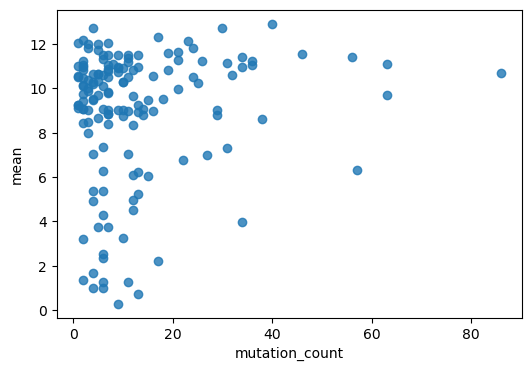

In [94]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_corr['mutation_count'], y=merge_corr['mean'], alpha=0.8)

ax.set_xlabel('mutation_count')
ax.set_ylabel('mean')
plt.show()


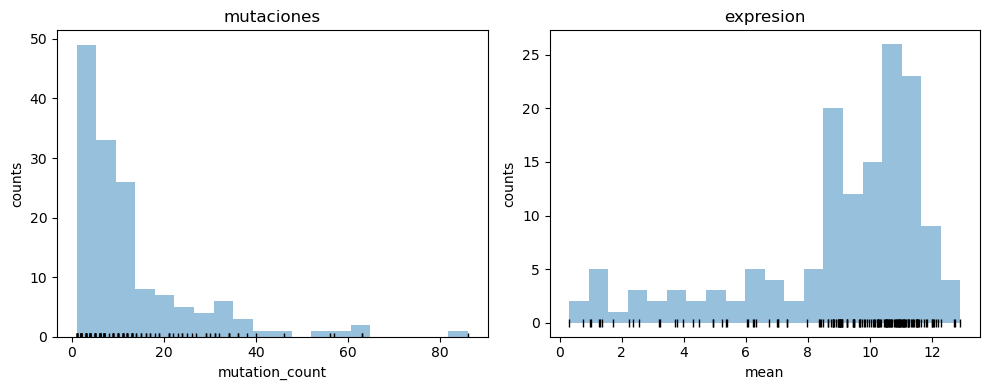

In [95]:
# Gráfico distribución variables
# ==============================================================================
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

axs[0].hist(x=merge_corr['mutation_count'], bins=20, color="#3182bd", alpha=0.5)
axs[0].plot(merge_corr['mutation_count'], np.full_like(merge_corr['mutation_count'], -0.01), '|k', markeredgewidth=1)
axs[0].set_title('mutaciones')
axs[0].set_xlabel('mutation_count')
axs[0].set_ylabel('counts')

axs[1].hist(x=merge_corr['mean'], bins=20, color="#3182bd", alpha=0.5)
axs[1].plot(merge_corr['mean'], np.full_like(merge_corr['mean'], -0.01), '|k', markeredgewidth=1)
axs[1].set_title('expresion')
axs[1].set_xlabel('mean')
axs[1].set_ylabel('counts')


plt.tight_layout();

In [96]:
import statsmodels.api as sm
import pingouin as pg
from scipy import stats
from scipy.stats import pearsonr

# Cálculo de correlación, significancia e intervalos con pingouin
# ==============================================================================
display(pg.corr(merge_corr['mutation_count'], merge_corr['mean'], method='pearson'))
display(pg.corr(merge_corr['mutation_count'], merge_corr['mean'], method='spearman'))
display(pg.corr(merge_corr['mutation_count'], merge_corr['mean'], method='kendall'))

,n,r,CI95%,p-val,BF10,power
pearson,148,0.137242,"[-0.02, 0.29]",0.096244,0.405,0.385223


,n,r,CI95%,p-val,power
spearman,148,0.091878,"[-0.07, 0.25]",0.266731,0.199376


,n,r,CI95%,p-val,power
kendall,148,0.06267,"[-0.1, 0.22]",0.268544,0.117822


# 2. Correlacion tumor/normal

In [162]:
exp_mean = df_xena_exp.groupby(['Gene', '_primary_site', '_sample_type'])['Normalized Expression'].agg(['mean', 'std']).reset_index()
exp_mean

,Gene,_primary_site,_sample_type,mean,std
0,ACVR1,Bladder,Normal Tissue,10.145222,0.245572
1,ACVR1,Bladder,Primary Tumor,9.797885,0.755207
2,ACVR1,Blood,Normal Tissue,8.111611,0.627104
3,ACVR1,Brain,Normal Tissue,9.251848,0.800205
4,ACVR1,Brain,Primary Tumor,10.100094,0.450888
...,...,...,...,...,...
343,TGFBR2,Skin,Primary Tumor,11.531186,1.076080
344,TGFBR2,Stomach,Normal Tissue,12.640057,1.452422
345,TGFBR2,Stomach,Primary Tumor,12.710051,0.946084
346,TGFBR2,Uterus,Normal Tissue,13.077564,0.510381


In [173]:
# Realizar el pivot para reorganizar los datos
pivot_df = exp_mean.pivot(index=['Gene', '_primary_site'], columns='_sample_type', values='mean').reset_index()

# Renombrar las columnas para mayor claridad
pivot_df.columns.name = None  # Elimina el nombre de las columnas después del pivot
pivot_df.rename(columns={'Normal Tissue': 'Mean Normal Tissue', 'Primary Tumor': 'Mean Primary Tumor'}, inplace=True)

# Mostrar el DataFrame resultante
pivot_df.fillna(0, inplace=True)
#Diferencia Tumor-Normal
pivot_df['tum/norm'] = pivot_df['Mean Primary Tumor']/pivot_df['Mean Normal Tissue']
pivot_df

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,tum/norm
0,ACVR1,Bladder,10.145222,9.797885,0.965763
1,ACVR1,Blood,8.111611,0.000000,0.000000
2,ACVR1,Brain,9.251848,10.100094,1.091684
3,ACVR1,Breast,10.471000,10.510159,1.003740
4,ACVR1,Cervix,0.000000,10.065655,inf
...,...,...,...,...,...
187,TGFBR2,Pancreas,12.102814,12.919663,1.067492
188,TGFBR2,Prostate,12.300910,11.064659,0.899499
189,TGFBR2,Skin,12.108056,11.531186,0.952357
190,TGFBR2,Stomach,12.640057,12.710051,1.005537


In [175]:
merge_tumor_normal = pivot_df.merge(df_mut, left_on=['Gene', '_primary_site'], right_on=['Gen_names', 'ColumnaTraducida'])
merge_tumor_normal.sort_values(by='mutation_count', ascending=False)

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,tum/norm,tipo_cancer,Gen_names,mutation_count,mutation_frequency,ColumnaTraducida
128,TGFBR1,Colon,10.981036,10.689406,0.973442,Colon,TGFBR1,86,0.085149,Colon
68,ACVRL1,Lung,13.023194,9.682132,0.743453,Pulmon,ACVRL1,63,0.062376,Lung
18,ACVR1B,Lung,10.676500,11.097222,1.039406,Pulmon,ACVR1B,63,0.062376,Lung
30,ACVR1C,Lung,4.681375,6.317033,1.349397,Pulmon,ACVR1C,57,0.056436,Lung
14,ACVR1B,Colon,10.341127,11.401278,1.102518,Colon,ACVR1B,56,0.055446,Colon
...,...,...,...,...,...,...,...,...,...,...
50,ACVR2B,Breast,8.744670,9.263777,1.059363,Seno,ACVR2B,1,0.000990,Breast
58,ACVR2B,Prostate,8.806300,9.093261,1.032586,Prostata,ACVR2B,1,0.000990,Prostate
35,ACVR2A,Bladder,9.996889,9.262174,0.926506,Vejiga,ACVR2A,1,0.000990,Bladder
2,ACVR1,Breast,10.471000,10.510159,1.003740,Seno,ACVR1,1,0.000990,Breast


In [176]:
import numpy as np

# Calcular el logaritmo base 10 de la columna 'mean'
merge_tumor_normal['log_tum_norm'] = np.log10(merge_tumor_normal['tum/norm'])
merge_tumor_normal['mutation_count_log'] = np.log10(merge_tumor_normal['mutation_count'])
merge_tumor_normal

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,tum/norm,tipo_cancer,Gen_names,mutation_count,mutation_frequency,ColumnaTraducida,log_tum_norm,mutation_count_log
0,ACVR1,Bladder,10.145222,9.797885,0.965763,Vejiga,ACVR1,7,0.006931,Bladder,-0.015129,0.845098
1,ACVR1,Brain,9.251848,10.100094,1.091684,Cerebro,ACVR1,6,0.005941,Brain,0.038097,0.778151
2,ACVR1,Breast,10.471000,10.510159,1.003740,Seno,ACVR1,1,0.000990,Breast,0.001621,0.000000
3,ACVR1,Colon,9.687701,9.837003,1.015412,Colon,ACVR1,7,0.006931,Colon,0.006642,0.845098
4,ACVR1,Head and Neck region,0.000000,10.629529,inf,Cabeza,ACVR1,5,0.004950,Head and Neck region,inf,0.698970
...,...,...,...,...,...,...,...,...,...,...,...,...
143,TGFBR2,Kidney,12.220357,12.734579,1.042079,Riñon,TGFBR2,4,0.003960,Kidney,0.017901,0.602060
144,TGFBR2,Lung,13.577118,11.831214,0.871408,Pulmon,TGFBR2,24,0.023762,Lung,-0.059778,1.380211
145,TGFBR2,Ovary,11.410023,11.220501,0.983390,Ovario,TGFBR2,2,0.001980,Ovary,-0.007274,0.301030
146,TGFBR2,Pancreas,12.102814,12.919663,1.067492,Pancreas,TGFBR2,40,0.039604,Pancreas,0.028365,1.602060


## Logaritmo

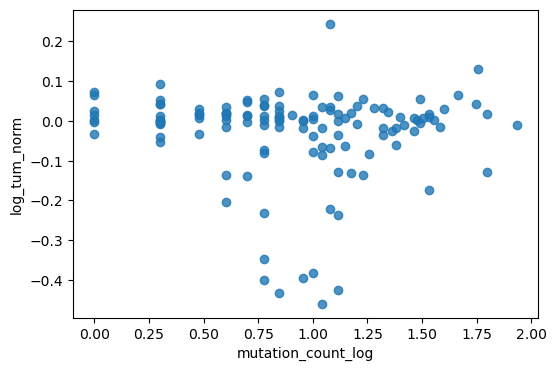

In [179]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_tumor_normal['mutation_count_log'], y=merge_tumor_normal['log_tum_norm'], alpha=0.8)

ax.set_xlabel('mutation_count_log')
ax.set_ylabel('log_tum_norm')
plt.show()


## Normal

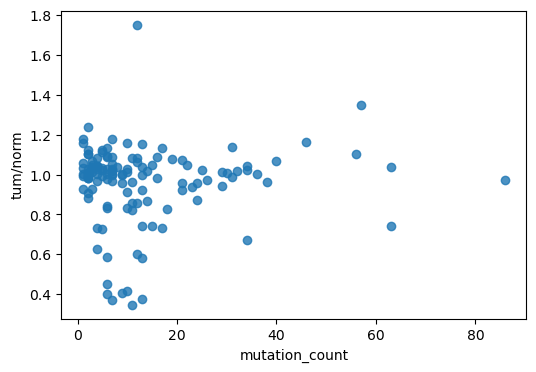

In [183]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_tumor_normal['mutation_count'], y=merge_tumor_normal['tum/norm'], alpha=0.8)

ax.set_xlabel('mutation_count')
ax.set_ylabel('tum/norm')
plt.show()


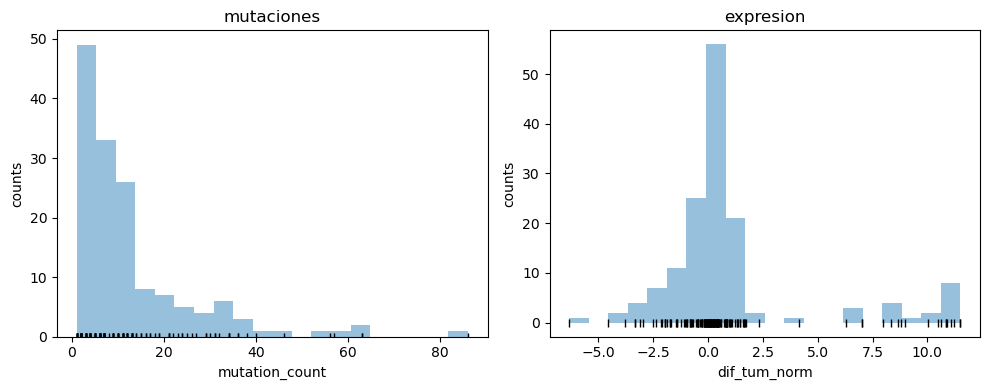

In [170]:
# Gráfico distribución variables
# ==============================================================================
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

axs[0].hist(x=merge_tumor_normal['mutation_count'], bins=20, color="#3182bd", alpha=0.5)
axs[0].plot(merge_tumor_normal['mutation_count'], np.full_like(merge_tumor_normal['mutation_count'], -0.01), '|k', markeredgewidth=1)
axs[0].set_title('mutaciones')
axs[0].set_xlabel('mutation_count')
axs[0].set_ylabel('counts')

axs[1].hist(x=merge_tumor_normal['dif_tum_norm'], bins=20, color="#3182bd", alpha=0.5)
axs[1].plot(merge_tumor_normal['dif_tum_norm'], np.full_like(merge_tumor_normal['dif_tum_norm'], -0.01), '|k', markeredgewidth=1)
axs[1].set_title('expresion')
axs[1].set_xlabel('dif_tum_norm')
axs[1].set_ylabel('counts')


plt.tight_layout();

In [185]:
# Cálculo de correlación con Pandas
# ==============================================================================
print('Correlación Pearson: ', merge_tumor_normal['mutation_count'].corr(merge_tumor_normal['dif_tum_norm'], method='pearson'))
print('Correlación spearman: ', merge_tumor_normal['mutation_count'].corr(merge_tumor_normal['dif_tum_norm'], method='spearman'))
print('Correlación kendall: ', merge_tumor_normal['mutation_count'].corr(merge_tumor_normal['dif_tum_norm'], method='kendall'))

KeyError: 'dif_tum_norm'

In [184]:
import statsmodels.api as sm
import pingouin as pg
from scipy import stats
from scipy.stats import pearsonr

# Cálculo de correlación, significancia e intervalos con pingouin
# ==============================================================================
display(pg.corr(merge_tumor_normal['mutation_count'], merge_tumor_normal['tum/norm'], method='pearson'))
display(pg.corr(merge_tumor_normal['mutation_count'], merge_tumor_normal['tum/norm'], method='spearman'))
display(pg.corr(merge_tumor_normal['mutation_count'], merge_tumor_normal['tum/norm'], method='kendall'))

/opt/homebrew/Caskroom/miniconda/base/envs/tk/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4788: RuntimeWarning: invalid value encountered in subtract
  ym = y.astype(dtype) - ymean


Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/opt/homebrew/Caskroom/miniconda/base/envs/tk/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5988/862790580.py", line 8, in <module>
    display(pg.corr(merge_tumor_normal['mutation_count'], merge_tumor_normal['tum/norm'], method='pearson'))
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/Caskroom/miniconda/base/envs/tk/lib/python3.11/site-packages/pingouin/correlation.py", line 604, in corr
    r, pval = pearsonr(x, y)
              ^^^^^^^^^^^^^^
  File "/opt/homebrew/Caskroom/miniconda/base/envs/tk/lib/python3.11/site-packages/scipy/stats/_stats_py.py", line 4794, in pearsonr
    normym = linalg.norm(ym)
             ^^^^^^^^^^^^^^^
  File "/opt/homebrew/Caskroom/miniconda/base/envs/tk/lib/python3.11/s

# 3. Buscar mutaciones por dominios

In [109]:
df= pd.read_csv('../data/mutaciones/df_frecuencias_mut_STKR.csv')
df

,Gen_names,icgc_donor_id,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,%mutant_allele_frequency,clasificacion
0,BMPR1A,DO28154,K372I,1115A>T,A,T,missense_variant,OV-US,Ovario,344.0,9.0,0.026163,2.616279,Baja frecuencia
1,TGFBR1,DO23786,S416F,1247C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,2.793296,Baja frecuencia
2,TGFBR1,DO23786,S347F,1040C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,2.793296,Baja frecuencia
3,TGFBR1,DO23786,S339F,1016C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,2.793296,Baja frecuencia
4,TGFBR1,DO23786,S420F,1259C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,2.793296,Baja frecuencia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3116,BMPR1A,DO219727,Q22*,64C>T,C,T,stop_gained,CESC-US,Cervix,32.0,30.0,0.937500,93.750000,Muy alta frecuencia
3117,BMPR2,DO37827,S233F,698C>T,C,T,missense_variant,SKCM-US,Piel,186.0,178.0,0.956989,95.698925,Muy alta frecuencia
3118,TGFBR1,DO35406,C98Y,293G>A,G,A,missense_variant,PACA-CA,Pancreas,40.0,40.0,1.000000,100.000000,Muy alta frecuencia
3119,TGFBR1,DO35406,C101Y,302G>A,G,A,missense_variant,PACA-CA,Pancreas,120.0,120.0,1.000000,100.000000,Muy alta frecuencia


In [114]:
df_mutaciones = df[['Gen_names', 'tipo_cancer', 'aa_mutation']]

In [116]:
df_mutaciones.drop_duplicates(subset=['Gen_names', 'tipo_cancer', 'aa_mutation'], inplace = True)
df_mutaciones

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5988/2057905889.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mutaciones.drop_duplicates(subset=['Gen_names', 'tipo_cancer', 'aa_mutation'], inplace = True)


,Gen_names,tipo_cancer,aa_mutation
0,BMPR1A,Ovario,K372I
1,TGFBR1,Pulmon,S416F
2,TGFBR1,Pulmon,S347F
3,TGFBR1,Pulmon,S339F
4,TGFBR1,Pulmon,S420F
...,...,...,...
3116,BMPR1A,Cervix,Q22*
3117,BMPR2,Piel,S233F
3118,TGFBR1,Pancreas,C98Y
3119,TGFBR1,Pancreas,C101Y


In [140]:
import pandas as pd

# Definir una función para extraer los números de la mutación
def extract_pos(aa_mutation):
    return ''.join(filter(str.isdigit, aa_mutation))

# Aplicar la función a la columna 'aa_mutation' y crear la nueva columna 'mutation_location'
df_mutaciones['pos'] = df_mutaciones['aa_mutation'].apply(extract_pos)

# Función para extraer la letra izquierda y derecha de la mutación
def extract_ref_mut(aa_mutation):
    # Extraer la posición (números)
    mutation_number = ''.join(filter(str.isdigit, aa_mutation))
    
    # Encontrar la posición de los números en la cadena
    number_index = aa_mutation.find(mutation_number)
    
    # Extraer la letra izquierda y derecha
    ref = aa_mutation[number_index - 1] if number_index > 0 else None
    mutation = aa_mutation[number_index + len(mutation_number)] if number_index + len(mutation_number) < len(aa_mutation) else None
    
    return ref, mutation

# Aplicar la función y crear las nuevas columnas 'pos' y 'ref'
df_mutaciones[['ref', 'mutation']] = df_mutaciones['aa_mutation'].apply(lambda x: pd.Series(extract_ref_mut(x)))

# Eliminar duplicados

df_mutaciones.drop_duplicates(['Gen_names', 'aa_mutation',  'tipo_cancer', 'pos', 'ref', 'mutation'], inplace=True)

# Mostrar el DataFrame resultante
df_mutaciones


/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5988/2394448221.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mutaciones['pos'] = df_mutaciones['aa_mutation'].apply(extract_pos)
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5988/2394448221.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mutaciones[['ref', 'mutation']] = df_mutaciones['aa_mutation'].apply(lambda x: pd.Series(extract_ref_mut(x)))
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5988/239444822

,Gen_names,tipo_cancer,aa_mutation,pos,ref,mutation
0,BMPR1A,Ovario,K372I,372,K,I
1,TGFBR1,Pulmon,S416F,416,S,F
2,TGFBR1,Pulmon,S347F,347,S,F
3,TGFBR1,Pulmon,S339F,339,S,F
4,TGFBR1,Pulmon,S420F,420,S,F
...,...,...,...,...,...,...
3116,BMPR1A,Cervix,Q22*,22,Q,*
3117,BMPR2,Piel,S233F,233,S,F
3118,TGFBR1,Pancreas,C98Y,98,C,Y
3119,TGFBR1,Pancreas,C101Y,101,C,Y


In [154]:
# Crea un diccionario para almacenar los DataFrames por gen
df_genes = {}

# Agrupa por 'Gen_names' y crea un DataFrame para cada grupo
for gen, grupo in df_mutaciones.groupby('Gen_names'):
    df_genes[gen] = grupo.reset_index(drop=True)

# Imprimir DataFrames para cada gen
for gen, df_gen in df_genes.items():
    print(f"DataFrame para {gen}:")
    #print(df_gen, "\n")

DataFrame para ACVR1:
DataFrame para ACVR1B:
DataFrame para ACVR1C:
DataFrame para ACVR2A:
DataFrame para ACVR2B:
DataFrame para ACVRL1:
DataFrame para AMHR2:
DataFrame para BMPR1A:
DataFrame para BMPR1B:
DataFrame para BMPR2:
DataFrame para TGFBR1:
DataFrame para TGFBR2:


In [155]:
df_genes['ACVR1']

,Gen_names,tipo_cancer,aa_mutation,pos,ref,mutation
0,ACVR1,Vejiga,G325E,325,G,E
1,ACVR1,Higado,G43D,43,G,D
2,ACVR1,Estomago,L141Q,141,L,Q
3,ACVR1,Estomago,V162M,162,V,M
4,ACVR1,Pulmon,F246S,246,F,S
...,...,...,...,...,...,...
90,ACVR1,Piel,P17S,17,P,S
91,ACVR1,Ovario,R375C,375,R,C
92,ACVR1,Pulmon,R401S,401,R,S
93,ACVR1,Vejiga,G88V,88,G,V


## Kinase doamin
 **ACVR1** = 186-496
 


In [159]:
# Filtra usando loc
df_acvr1_filtrado = df_genes['ACVR1'].loc[df_genes['ACVR1']['pos'] > 185]


TypeError: '>' not supported between instances of 'str' and 'int'